# Week 6 Assignment 
## Data 620
### Jane Song

## Assignment task
Here is a dataset that shows a simple 2-node network:  the attendance of 18 Southern Women at 14 social events:

    Brief Description. Small “musty” datasets like that from this 1941 study have proven very valuable in testing and comparing new network algorithms.
    Dataset.
    Python code to create dataset: https://networkx.github.io/documentation/stable/auto_examples/algorithms/plot_davis_club.html

What can you infer about the relationships between (1) the women, and (2) the social events?  

Biadjacency matrix
<Compressed Sparse Row sparse array of dtype 'int64'
	with 89 stored elements and shape (18, 14)>
  Coords	Values
  (0, 0)	1
  (0, 1)	1
  (0, 2)	1
  (0, 3)	1
  (0, 4)	1
  (0, 5)	1
  (0, 7)	1
  (0, 8)	1
  (1, 0)	1
  (1, 1)	1
  (1, 2)	1
  (1, 4)	1
  (1, 5)	1
  (1, 6)	1
  (1, 7)	1
  (2, 1)	1
  (2, 2)	1
  (2, 3)	1
  (2, 4)	1
  (2, 5)	1
  (2, 6)	1
  (2, 7)	1
  (2, 8)	1
  (3, 0)	1
  (3, 2)	1
  :	:
  (12, 7)	1
  (12, 8)	1
  (12, 9)	1
  (12, 11)	1
  (12, 12)	1
  (12, 13)	1
  (13, 5)	1
  (13, 6)	1
  (13, 8)	1
  (13, 9)	1
  (13, 10)	1
  (13, 11)	1
  (13, 12)	1
  (13, 13)	1
  (14, 6)	1
  (14, 7)	1
  (14, 9)	1
  (14, 10)	1
  (14, 11)	1
  (15, 7)	1
  (15, 8)	1
  (16, 8)	1
  (16, 10)	1
  (17, 8)	1
  (17, 10)	1

#Friends, Member
17 Evelyn Jefferson
15 Laura Mandeville
17 Theresa Anderson
15 Brenda Rogers
11 Charlotte McDowd
15 Frances Anderson
15 Eleanor Nye
16 Pearl Oglethorpe
17 Ruth DeSand
17 Verne Sanderson
16 Myra Liddel
16 Katherina Rogers
17 Sylvia Avondale
17 Nora Fayette
1

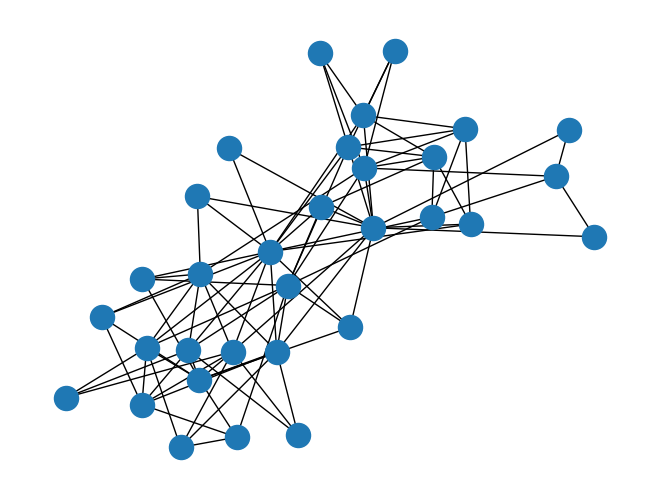

In [ ]:
# Code from assignment link 
import matplotlib.pyplot as plt
import networkx as nx
from networkx.algorithms import bipartite

G = nx.davis_southern_women_graph()
women = G.graph["top"]
clubs = G.graph["bottom"]

print("Biadjacency matrix")
print(bipartite.biadjacency_matrix(G, women, clubs))

# project bipartite graph onto women nodes
W = bipartite.projected_graph(G, women)
print()
print("#Friends, Member")
for w in women:
    print(f"{W.degree(w)} {w}")

# project bipartite graph onto women nodes keeping number of co-occurrence
# the degree computed is weighted and counts the total number of shared contacts
W = bipartite.weighted_projected_graph(G, women)
print()
print("#Friend meetings, Member")
for w in women:
    print(f"{W.degree(w, weight='weight')} {w}")

pos = nx.spring_layout(G, seed=648)  # Seed layout for reproducible node positions
nx.draw(G, pos)
plt.show()

From the original code and network map provided, we can see there is overlap between all the nodes of women and events. To further analyse the relationship between women and events, we can use degree centrality to identify the events attended by many women and the women attending many events.

## Degree centrality 

In [ ]:
# Degree centrality 
import pandas as pd
degree_centrality = nx.degree_centrality(G)

centrality_df = pd.DataFrame({
    "Node": list(G.nodes()),
    "Type": [
        "Woman" if node in women else "Event"
        for node in G.nodes()],
        
    "Degree_Centrality": [
        degree_centrality[node] for node in G.nodes()
    ]})

centrality_df.sort_values(
    "Degree_Centrality", ascending=False
)

,Node,Type,Degree_Centrality
25,E8,Event,0.451613
26,E9,Event,0.387097
24,E7,Event,0.322581
0,Evelyn Jefferson,Woman,0.258065
22,E5,Event,0.258065
2,Theresa Anderson,Woman,0.258065
13,Nora Fayette,Woman,0.258065
23,E6,Event,0.258065
12,Sylvia Avondale,Woman,0.225806
3,Brenda Rogers,Woman,0.225806


We can see that the the event 8 node has the highest degree centrality for events. For women, we can see that Evelyn Jefferson, Thersa Anderson, and Nora Fayette have the highest degree centrality. This implies that they are connected to the highest number of events and E8 is connected to the greatest number of women. 

## Network diameter

In [ ]:
# Check connection and diameter
print("Number of connected components:", nx.number_connected_components(G))

if nx.is_connected(G):
    print("Network diameter:", nx.diameter(G))
else:
    largest_component = G.subgraph(
        max(nx.connected_components(G), key=len)
    )
    print(
        "Diameter of largest connected component:",
        nx.diameter(largest_component)
    )

Number of connected components: 1
Network diameter: 4


The network has one connected component, meaning all the women and events are connected through at least one path. The network diameter is 4, indicating that the maximum length of the shortest path between any two nodes is four edges. This suggests that the network is relatively interconnected, with connections between women and events linking the overall social network.

## Visualized network 

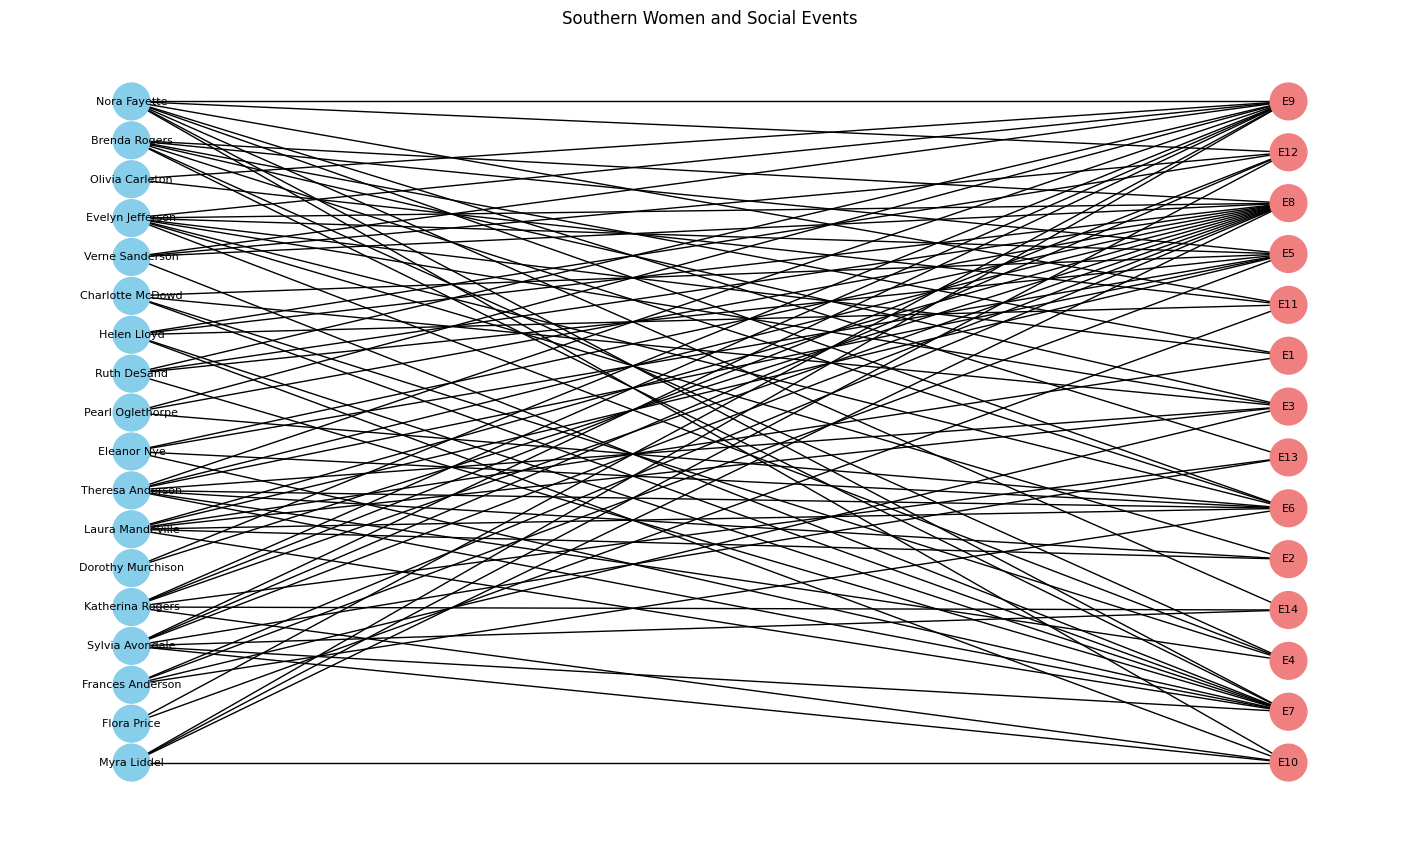

In [8]:
pos = nx.bipartite_layout(G, women)

node_colors = [
    "skyblue" if node in women else "lightcoral"
    for node in G.nodes()
]

plt.figure(figsize=(14, 8))
nx.draw(
    G,
    pos,
    with_labels=True,
    node_color=node_colors,
    node_size=700,
    font_size=8
)

plt.title("Southern Women and Social Events")
plt.show()

A visualization splitting the nodes by women and events also helps us see the relationships more clearly. In this visual, the findings from the degree centrality results are confirmed and we see that E8 was the most popular event. Among women, this also confirms that Evelyn, Theresa, and Nora are most directly connected to events.  

## Conclusion 

The network visualization helps show the relationships between the 18 women and 14 social events. The degree centrality results show that E8 was the most popular event, while Evelyn, Theresa, and Nora had the most direct connections to events. These attendance patterns suggest that some women participated in more social activities than others, and shared attendance may indicate opportunities for interaction between women. The network has one connected component, meaning all women and events are connected through at least one path. The network diameter is 4, indicating that the maximum length of the shortest path between any two nodes is four edges. 

Overall, the network shows that the women and events are interconnected with overlapping attendance patterns potentially providing insight into the social circles of this group.